In [2]:
from rdkit import Chem
from rdkit.Chem.rdFMCS import FindMCS
from rdkit import RDLogger
import numpy as np
import sys
import time
from anytree import Node, RenderTree
sys.path.append('molecule-web-app/backend/rules')  # replace with your local path
sys.path.append('molecule-web-app/backend')
# Now you can import your module as usual
from rules import execute_step, run_next_step
import helper
from ml_helper import make_fingerprint
from next_step import follow_on

import xgboost
import pickle

In [64]:
# Load the model
clf = xgboost.XGBClassifier()
clf.load_model('models/v53/xg_model.json')

In [104]:
sm_smiles = 'CC(=O)CCC(=O)C.[NH4+]'
end_smiles = 'C1=C(C)NC(C)=C1.O.[OH3+]'
sm = Chem.MolFromSmiles(sm_smiles)
end = Chem.MolFromSmiles(end_smiles)
sm_node = Node("SM", mol=sm)


In [105]:
# Parameters
force_depth = True
depth_limit = 6
boost = 0
resort_limit = 1000000
force_correct_last_step = True
aromatic = True
follow_on_enabled = True 
# Initialise variables
step_no = 0
product_nodes = []
times_per_layer = []
nodes = [sm_node]
signal_break = False
unique_id = 0
current_max_depth = 0
best_node = None
highest_sim = 0

duplicate_count = 0
inchi_keys = set()

inchi2 = Chem.MolToInchi(end, options='/FixedH')
RDLogger.DisableLog('rdApp.*') 
while step_no < depth_limit:
    product_count = 0
    start_t = time.time()
    print(f'step no {step_no + 1}')
    for int in nodes:
        if hasattr(int, 'product'):
            continue
        try:
            product_mols, mechs, mol_inp  = run_next_step("Placeholder", aromatic, True, int.mol)
        except Exception as e:
            continue
        for i, product in enumerate(product_mols):
            fp = np.array(make_fingerprint(mol_inp, mechs[i]))
            pred = clf.predict(fp.reshape(1,-1))[0]
            try:
                inchi1 = Chem.MolToInchi(product, options='/FixedH')
                # if inchi1 in inchi_keys:
                #     duplicate_count += 1
                #     continue
                # else:
                #     inchi_keys.add(inchi1)
            except Exception as e:
                print(f'Error processing product {i}: {e}')
                continue
            if inchi1 == inchi2:
                print('Found the target molecule!')
                print(f'The final step (mol {unique_id}) was predicted: {pred}')
                if force_correct_last_step and pred != 1:
                        continue
                unique_id += 1
                new_node = Node(f"Mol {unique_id}", parent=int, mol=product, mech=mechs[i])
                new_node.product = True
                product_nodes.append(new_node)
                if not (force_depth and step_no < depth_limit):
                    signal_break = True
                break
            elif pred == 1:
                unique_id += 1
                new_node = Node(f"Mol {unique_id}", parent=int, mol=product, mech=mechs[i])
                if follow_on_enabled:
                    f_nodes = []
                    try:
                        f_mols, f_smiles = follow_on(product, mechs[i], clf)
                    except:
                        print("issue with follow on mol")
                    for fm in f_mols:
                        try:
                            inchi1 = Chem.MolToInchi(fm, options='/FixedH')
                        except Exception as e:
                            print(f'Error processing product {i}: {e}')
                            continue
                        # if inchi1 in inchi_keys:
                        #     duplicate_count += 1
                        #     continue
                        # else:
                        #     inchi_keys.add(inchi1)
                        unique_id += 1
                        f_node = Node(f"Mol {unique_id}", parent=int, mol=fm, mech="follow_on")
                        f_nodes.append(f_node)
                        
                        if inchi1 == inchi2:
                            print('Found the target molecule!')
                            f_node.product = True
                            print(f_node)
                            product_nodes.append(f_node)
                   
                    if not(force_depth and step_no < depth_limit):
                        signal_break = True
                        break
                
        
                    
        if signal_break:
            break
                
        if not int.children and not hasattr(int, 'product'):
            int.parent = None  # Remove node if it has no children
            #print(f'Removed node {int.name} due to no children')
        if signal_break:
            break
    if signal_break:
        print("we breaking")
        break
    
    print(sm_node.leaves[0].depth)
    if sm_node.leaves[0].depth < step_no:
        print("no more products can be formed, ending search")
        break
    nodes = sm_node.leaves
    #nodes = sorted(nodes, key=lambda x: x.priority)
    step_no += 1
    end_t = time.time()
    times_per_layer.append(end_t - start_t)

print("search is over")

       


step no 1
1
step no 2
2
step no 3
3
step no 4
4
step no 5
Found the target molecule!
The final step (mol 12115) was predicted: 0
5
step no 6
Found the target molecule!
The final step (mol 60594) was predicted: 0
Found the target molecule!
The final step (mol 115752) was predicted: 0
Found the target molecule!
The final step (mol 127278) was predicted: 0
Found the target molecule!
The final step (mol 136690) was predicted: 0
Found the target molecule!
The final step (mol 140333) was predicted: 0
Found the target molecule!
The final step (mol 150023) was predicted: 0
Found the target molecule!
The final step (mol 150437) was predicted: 1
Found the target molecule!
The final step (mol 151969) was predicted: 1
Found the target molecule!
The final step (mol 152060) was predicted: 0
Found the target molecule!
The final step (mol 152344) was predicted: 0
Found the target molecule!
The final step (mol 152380) was predicted: 0
Found the target molecule!
The final step (mol 152406) was predicted

In [77]:
print(len(product_nodes))
clean_nodes = []
for p_node in product_nodes:
    path = []
    current = p_node
    while current is not None:
        path.append(Chem.MolToInchi(current.mol, options='/FixedH'))
        current = current.parent
    if len(set(path)) < len(path):
        print("Duplicate molecule in path detected:")
        print(p_node)
    else:
        clean_nodes.append(p_node)
print(len(clean_nodes))

93
Duplicate molecule in path detected:
Node('/SM/Mol 1/Mol 4/Mol 28/Mol 268/Mol 2627/Mol 26512', mech=[8, 0, 3, 1, 2], mol=<rdkit.Chem.rdchem.Mol object at 0x7f62a2de86d0>, product=True)
Duplicate molecule in path detected:
Node('/SM/Mol 1/Mol 4/Mol 32/Mol 325/Mol 3315/Mol 34299', mech=[8, 0, 3, 1, 2], mol=<rdkit.Chem.rdchem.Mol object at 0x7f62a208cc80>, product=True)
Duplicate molecule in path detected:
Node('/SM/Mol 1/Mol 4/Mol 35/Mol 388/Mol 4161/Mol 44903', mech=[8, 0, 3, 1, 2], mol=<rdkit.Chem.rdchem.Mol object at 0x7f629a9119a0>, product=True)
Duplicate molecule in path detected:
Node('/SM/Mol 1/Mol 4/Mol 47/Mol 509/Mol 5468/Mol 58909', mech=[8, 0, 3, 1, 2], mol=<rdkit.Chem.rdchem.Mol object at 0x7f62a23e8660>, product=True)
Duplicate molecule in path detected:
Node('/SM/Mol 1/Mol 6/Mol 51/Mol 554/Mol 5971/Mol 64347', mech=[8, 0, 3, 1, 2], mol=<rdkit.Chem.rdchem.Mol object at 0x7f62a2cdae30>, product=True)
Duplicate molecule in path detected:
Node('/SM/Mol 1/Mol 6/Mol 55/Mol 59

In [6]:
len(inchi_keys)

0

In [7]:
for i, dur in enumerate(times_per_layer):
    print(f'Layer {i+1} took {dur:.2f} seconds')

Layer 1 took 0.06 seconds
Layer 2 took 0.17 seconds
Layer 3 took 2.38 seconds
Layer 4 took 27.71 seconds


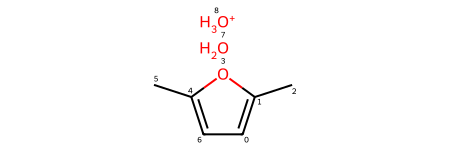

In [62]:
end

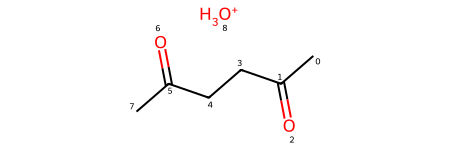

In [63]:
sm

In [10]:
sm_node.size

8316

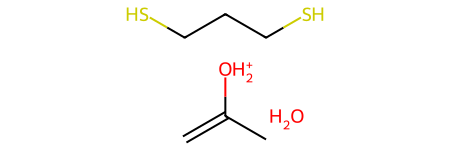

In [11]:
sm_node.leaves[7].mol


In [12]:
product_nodes[0]

Node('/SM/Mol 1/Mol 18/Mol 219', mech='follow_on', mol=<rdkit.Chem.rdchem.Mol object at 0x7f62c3366a20>, product=True)

In [13]:
def visualise_tree(node):
    mols = [node.mol]
    while node.is_root is False:
        node = node.parent
        mols.append(node.mol)
    mols.reverse()
    return Chem.Draw.MolsToGridImage(mols, molsPerRow=3, subImgSize=(400, 400), legends=[f"Mol {i}" for i in range(len(mols))])

In [14]:
def pickle_tree(node, name="reaction_path", idx=0):
    mols = [node.mol]
    while node.is_root is False:
        node = node.parent
        mols.append(node.mol)
    mols.reverse()
    pickle.dump(mols, open(f"{name}_{idx}.pkl", "wb"))
    print(f"Pickled reaction path {idx} to {name}_{idx}.pkl")
    return None

In [15]:
def visualise_tree_png(node):
    mols = [node.mol]
    while node.is_root is False:
        node = node.parent
        mols.append(node.mol)
    mols.reverse()
    return Chem.Draw.MolsToGridImage(mols, molsPerRow=3, subImgSize=(700, 700), legends=[f"Mol {i}" for i in range(len(mols))], returnPNG=True)

In [16]:
Chem.Draw.IPythonConsole.drawOptions.addAtomIndices  =True

In [17]:
#for i, p in enumerate(product_nodes):
#    pickle_tree(p, idx=i)

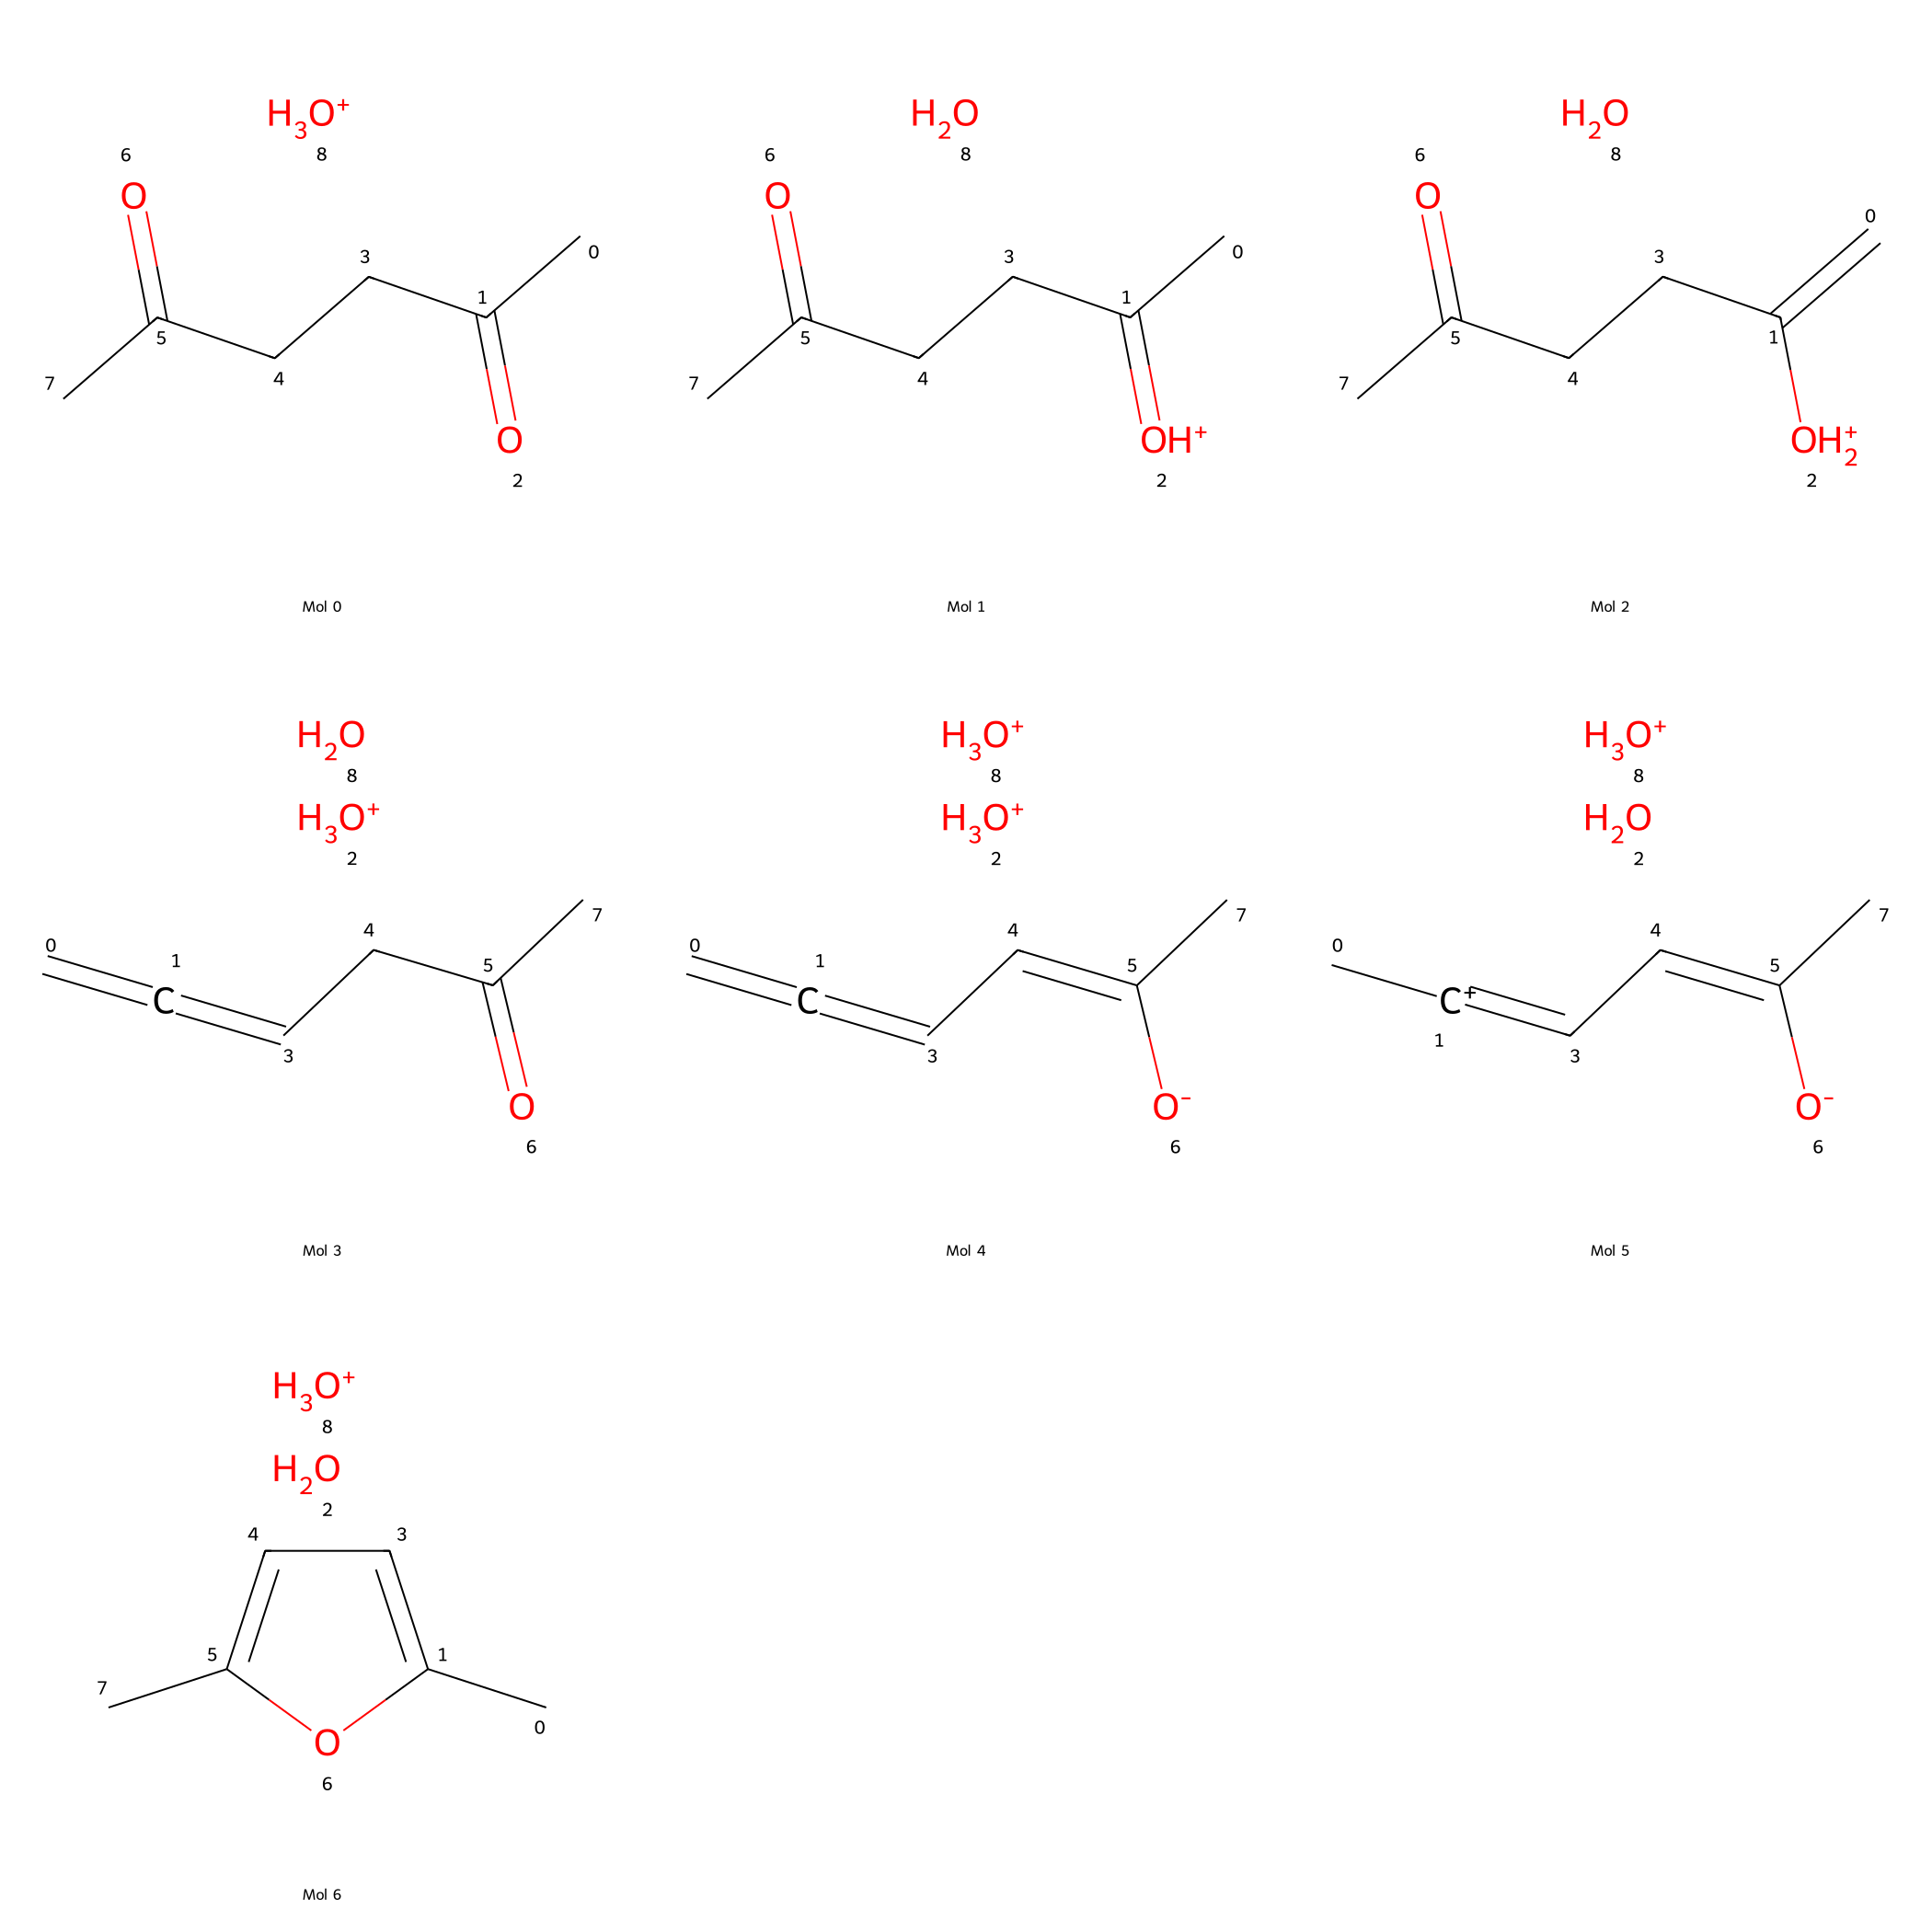

In [103]:
visualise_tree_png(clean_nodes[13])

In [38]:
for pre, fill, node in RenderTree(sm_node):
    print(f"{pre}{node.name} - {Chem.MolToSmiles(node.mol)}")
    #if hasattr(node, 'mech'):
    #    print(f"{pre}Mechanism: {node.mech}")
    #else:
    #    print(f"{pre}Mechanism: None")

SM - CC(C)=O.SCCCS.[OH3+]
├── Mol 1 - CC(C)=[OH+].O.SCCCS
│   ├── Mol 6 - C=C(C)O.O.SCCC[SH2+]
│   │   ├── Mol 20 - C=C(C)O.[OH-].[SH2+]CCC[SH2+]
│   │   │   ├── Mol 61 - C=C(C)O.OCCC[SH2+].S
│   │   │   │   ├── Mol 131 - C[C+](O)CCCCO.S.S
│   │   │   │   └── Mol 132 - CC(O)([SH2+])CCCCO.S
│   │   │   ├── Mol 62 - C[C+](O)CCCC[SH2+].S.[OH-]
│   │   │   │   ├── Mol 133 - CC(=[OH+])CCCC[SH2+].S.[OH-]
│   │   │   │   ├── Mol 134 - C=CCC[C+](C)O.S.[OH-].[SH3+]
│   │   │   │   └── Mol 135 - CC(O)(O)CCCC[SH2+].S
│   │   │   └── Mol 63 - CC(O)([SH2+])CCCC[SH2+].[OH-]
│   │   │       ├── Mol 136 - CC([OH2+])(S)CCCC[SH2+].[OH-]
│   │   │       ├── Mol 137 - CC1([SH2+])CCCC[OH+]1.S.[OH-]
│   │   │       └── Mol 138 - CC1([SH2+])CCCCO1.[OH-].[SH3+]
│   │   ├── Mol 21 - C=C(C)O.C=CCS.S.[OH3+]
│   │   │   ├── Mol 64 - C=CCS.C[C+](C)O.[OH3+].[SH-]
│   │   │   │   └── Mol 139 - C[C+](C)O.C[CH+]CS.O.[SH-]
│   │   │   └── Mol 65 - C=C(C)O.C[CH+]CS.O.S
│   │   │       ├── Mol 140 - C=C(C)[OH+]C(C)CS.O.S

In [26]:
product_nodes[0].parent.parent

Node('/SM', mol=<rdkit.Chem.rdchem.Mol object at 0x7f09ddb313f0>)

In [30]:
inp_mol = Chem.MolFromSmiles("CC(C)=[S+]CCCS.O.O")
try:
    product_mols, mechs, mol_inp  = run_next_step("Placeholder", aromatic, True, inp_mol)
except Exception as e:
    print("problem")
for i, product in enumerate(product_mols):
    fp = np.array(make_fingerprint(mol_inp, mechs[i]))
    pred = clf.predict(fp.reshape(1,-1))[0]
    try:
        inchi1 = Chem.MolToInchi(product, options='/FixedH')
        # if inchi1 in inchi_keys:
        #     duplicate_count += 1
        #     continue
        # else:
        #     inchi_keys.add(inchi1)
    except Exception as e:
        print(f'Error processing product {i}: {e}')
        continue
    
    if pred == 1:
        unique_id += 1
        new_node = Node(f"Mol {unique_id}", parent=int, mol=product, mech=mechs[i])
        print(Chem.MolToSmiles(product))

CC(C)=S1CCC[SH+]1.O.O
CC(C)=[S+]CCC[SH2+].O.[OH-]
C=C(C)SCCCS.O.[OH3+]
CC(C)=S([OH2+])CCCS.O
CC(C)=S=CCCS.O.[OH3+]
C=CCS.CC(C)=S.O.[OH3+]
CC(C)=[S+]CCCS.[OH-].[OH3+]
CC1(C)SCCC[SH+]1.O.O
CC(C)([OH2+])SCCCS.O
CC(C)=S.O.[OH2+]CCCS


In [18]:
Chem.Draw.MolsToGridImage([m.mol for m in best_node.children])
#best_node.depth

AttributeError: 'NoneType' object has no attribute 'children'

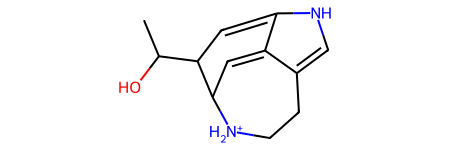

In [8]:
best_node.mol

In [13]:
execute_step('CC1=CCC([C+](C)C)CC1.O', True, False, None, False)

[9, 10, 4, 5, None]
[0, 10, 5, None, None]
[9, 10, 6, 5, None]
[1, 10, 1, None, 2]
[1, 10, 2, None, 1]
[9, 1, 4, 5, None]
[9, 2, 4, 5, None]
[1, 1, 5, 2, None]
[1, 2, 5, 1, None]
[9, 1, 6, 5, None]
[9, 2, 6, 5, None]
[5, 1, 10, 2, None]
[5, 2, 10, 1, None]


([<rdkit.Chem.rdchem.Mol at 0x7f86c92051c0>,
 [[9, 10, 4, 5, None],
  [0, 10, 5, None, None],
  [9, 10, 6, 5, None],
  [1, 10, 1, None, 2],
  [1, 10, 2, None, 1],
  [9, 1, 4, 5, None],
  [9, 2, 4, 5, None],
  [1, 1, 5, 2, None],
  [1, 2, 5, 1, None],
  [9, 1, 6, 5, None],
  [9, 2, 6, 5, None],
  [5, 1, 10, 2, None],
  [5, 2, 10, 1, None]],
 <rdkit.Chem.rdchem.Mol at 0x7f86c9204ba0>)

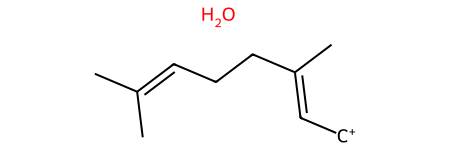

In [14]:
sm

In [15]:
mols, mechs, mol_inp = execute_step('O.CC(C)=CCCC(C)=C[CH2+]', True, False, None, False)

[9, 0, 9, 10, None]
[0, 0, 10, None, None]
[1, 0, 2, None, 4]
[1, 0, 4, None, 2]
[1, 0, 7, None, 9]
[1, 0, 9, None, 7]
[5, 2, 0, 4, None]
[5, 4, 0, 2, None]
[9, 2, 9, 10, None]
[9, 4, 9, 10, None]
[1, 2, 10, 4, None]
[1, 4, 10, 2, None]
[5, 7, 0, 9, None]
[5, 9, 0, 7, None]
[9, 7, 9, 10, None]
[1, 7, 10, 9, None]
[1, 9, 10, 7, None]
[3, 2, 7, 4, 9]
[3, 4, 7, 2, 9]
[3, 2, 9, 4, 7]
[3, 4, 9, 2, 7]
[3, 7, 2, 9, 4]
[3, 9, 2, 7, 4]
[3, 7, 4, 9, 2]
[3, 9, 4, 7, 2]


In [24]:
mols, mechs, mol_inp = execute_step('P', True, False, b, False)

[9, 0, 1, 2, None]
[0, 0, 2, None, None]
[9, 0, 4, 2, None]
[1, 0, 7, None, 9]
[1, 0, 9, None, 7]
[5, 7, 0, 9, None]
[5, 9, 0, 7, None]
[9, 7, 1, 2, None]
[9, 9, 1, 2, None]
[1, 7, 2, 9, None]
[1, 9, 2, 7, None]
[9, 7, 4, 2, None]
[9, 9, 4, 2, None]


In [16]:
for i, mol in enumerate(mols):
    fp = np.array(make_fingerprint(mol_inp, mechs[i]))
    if clf.predict(fp.reshape(1,-1))[0]==1:
        print(f'Predicted product {i} is a valid reaction product')

Predicted product 1 is a valid reaction product
Predicted product 11 is a valid reaction product


In [17]:
b = Chem.Mol(mols[11])

In [18]:
clf.predict(fp.reshape(1,-1))

array([0])

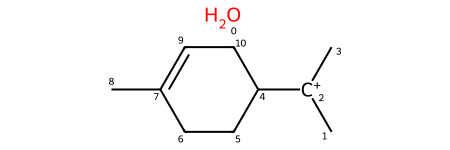

In [23]:
b

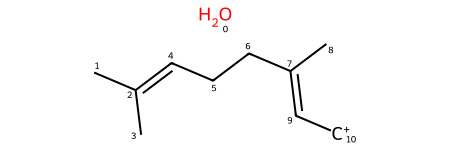

In [22]:
mol_inp

In [21]:
Chem.Draw.IPythonConsole.drawOptions.addAtomIndices = True

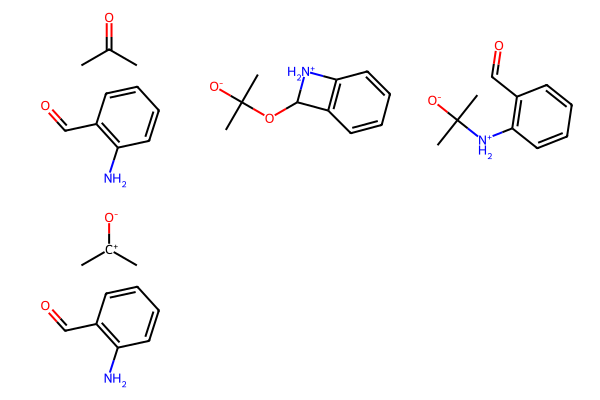

In [29]:
some_mols = [m.mol for m in new_node.parent.children]
Chem.Draw.MolsToGridImage(some_mols)

MCS: [#6]-[#6](:,-[#7]:,-[#6]1:[#6](:[#6]:[#6]:[#6]:[#6]:1):,-[#6]):,-[#6], num atoms: 11, num bonds: 11


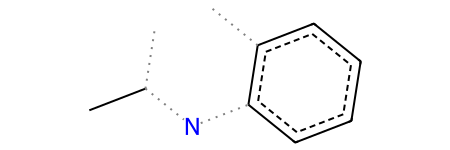

In [40]:
from rdkit.Chem.rdFMCS import FindMCS
result = FindMCS([some_mols[2], end])
print(f'MCS: {result.smartsString}, num atoms: {result.numAtoms}, num bonds: {result.numBonds}')
Chem.MolFromSmarts(result.smartsString)